# From one agent to a vLLM sweep (and a kernel)

A walkthrough of the numbers that matter for the next two stages of this project:

1. **Picking loose bounds for the vLLM sweep:** `max_num_seqs`, `max_num_batched_tokens`, `gpu_memory_utilization`,
   `kv_cache_dtype`, and how many agents to throw at the server.
2. **Deciding what a custom kernel should speed up:** where the GPU actually spends its time for *this* workload.

Every number here comes from your own runs: the agent traces, the harness results, the server's `/metrics` stream,
the server's startup log, and the model's `config.json`. Each chapter follows the same pattern:

- **The question.**
- **A picture** of the idea. Diagrams marked *schematic* show an idea with no data. Charts marked *your data* are drawn from your files.
- **Where the number lives:** the raw line or event it comes from.
- **The number for your runs.**
- **Why it matters next:** for the sweep, and for a kernel.

Some chapters have a **Try it**: work the number out yourself from what's on screen, then run the next cell to compare.

| Chapter | Question | Feeds |
|---|---|---|
| 1 | What does one agent run actually do? | everything below |
| 2 | What happens inside one model call? | TTFT, decode speed, kernels |
| 3 | What is the KV cache, and how big is it? | `gpu_memory_utilization`, `kv_cache_dtype` |
| 4 | How much KV cache does a request hold? | `max_num_seqs` |
| 5 | How many agents fit before the server saturates? | sweep points, `max_num_seqs` |
| 6 | How does the scheduler mix prefill and decode? | `max_num_batched_tokens` |
| 7 | Where does the GPU's time go? | the kernel |
| 8 | Putting it together | your loose bounds |

**Setup (once):** `uv pip install matplotlib ipykernel` in the repo venv, then pick that venv as the kernel in VS Code.
Run the cells top to bottom.

ACtual usage is 32.74 GB
current kv cache memory in usage is 36.62 gb
free memory on device 77.5/79.17 gb

In [7]:
%matplotlib inline
import sys, json, math, re, urllib.request
from collections import defaultdict
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from matplotlib.ticker import ScalarFormatter, NullLocator

ROOT = Path.cwd()
while not (ROOT / "Benchmarking").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from Benchmarking.analyze import read_jsonl, val, delta, label     # the same readers the analysis script uses
TRACING = ROOT / "tracing"

# ---- what to learn from --------------------------------------------------------------------------
TAGS = ["20261026_200252", "20261026_201733"]   # two back-to-back passes from one server boot (empty = every run in tracing/)
BOOT_LOG = None     # optional: path to a saved copy of the server's startup log (Chapter 3). Or fill in BOOT by hand there.
MODEL = "IFM/K2-Horizon-32B"

# approximate public peaks for one H100 SXM, used only for the back-of-envelope in Chapter 7
PEAK_TFLOPS_BF16 = 989.0      # dense bf16 matmul throughput, TFLOP/s
PEAK_HBM_TBPS = 3.35          # memory bandwidth, TB/s

# ---- look: the validated reference palette; series colors in a fixed order, grays for context --------
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
G1, G2, G3 = "#6b6a64", "#a3a29b", "#d3d2cb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "font.family": "sans-serif", "font.size": 10, "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
})

def style(ax, grid="y"):
    ax.grid(axis=grid, color=GRID, linewidth=0.8); ax.set_axisbelow(True); ax.tick_params(length=0)

def title(ax, text):
    ax.set_title(text, loc="left", fontsize=11, fontweight="bold", color=INK, pad=10)

def plain_log(axis, ticks):
    axis.set_ticks(list(ticks)); axis.set_major_formatter(ScalarFormatter()); axis.set_minor_locator(NullLocator())

def box(ax, x, y, w, h, text, fc=SURFACE, ec=AXIS, bold=False, fs=8.5, color=INK):
    ax.add_patch(Rectangle((x, y), w, h, fc=fc, ec=ec, lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal", color=color)

def arrow(ax, x0, y0, x1, y1, color=MUTED):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=color, lw=1.2))

def pct(v, p):
    return float(np.percentile(v, p)) if len(v) else None

# ---- load the runs ----------------------------------------------------------------------------------
def agent_shape(evs):
    """One agent run: its model calls and tool calls, with times relative to the run's start."""
    start = next(e for e in evs if e["type"] == "run_start")
    end = next(e for e in evs if e["type"] == "run_end")
    t0 = start["timestamp"]
    model = sorted(({"t": e["timestamp"] - t0, "len": e["latency_ms"] / 1000, "prompt": e["prompt_tokens"],
                     "out": e["completion_tokens"] or 0, "ttft": e["ttft_any_ms"], "ttft_vis": e["ttft_visible_ms"],
                     "decode_ms": e["decode_ms"], "finish": e["finish_reason"]}
                    for e in evs if e["type"] == "model" and e.get("prompt_tokens") is not None), key=lambda m: m["t"])
    tools = sorted(({"t": e["timestamp"] - t0, "len": e["latency_ms"] / 1000, "chars": e["result_chars"],
                     "hit": e.get("cache_hit")}
                    for e in evs if e["type"] == "tool"), key=lambda x: x["t"])
    return {"question": start["question"], "dur": end["duration_ms"] / 1000, "model": model, "tools": tools, "events": evs}

def load_passes(tags):
    found = [t for t in tags if (TRACING / f"results_{t}.json").exists()] or \
            sorted(p.stem[len("results_"):] for p in TRACING.glob("results_*.json"))
    passes = []
    for tag in found:
        res = json.loads((TRACING / f"results_{tag}.json").read_text())
        by_run = defaultdict(list)
        path = TRACING / f"traces_{tag}.jsonl"
        for e in (read_jsonl(path) if path.exists() else []):
            by_run[e["run_id"]].append(e)
        agents = [agent_shape(evs) for evs in by_run.values()
                  if any(e["type"] == "run_start" for e in evs) and any(e["type"] == "run_end" for e in evs)]
        passes.append({"tag": tag, "results": res, "agents": agents})
    return passes

PASSES = load_passes(TAGS)
AGENTS = [a for p in PASSES for a in p["agents"]]
CALLS = [m for a in AGENTS for m in a["model"]]
TOOLS = [t for a in AGENTS for t in a["tools"]]

mpath = TRACING / "vllm_metrics.jsonl"
SAMPLES = sorted(({"t": r["timestamp"], "m": r["metrics"]} for r in read_jsonl(mpath)), key=lambda r: r["t"]) if mpath.exists() else []

print(f"passes: {[p['tag'] for p in PASSES]}")
print(f"{len(AGENTS)} agent runs, {len(CALLS)} model calls, {len(TOOLS)} tool calls, {len(SAMPLES)} server metric samples")

passes: ['20261026_200252', '20261026_201733']
90 agent runs, 188 model calls, 158 tool calls, 2160 server metric samples


In [8]:
# ---- the server's view of each pass: everything /metrics recorded inside the pass's time window ------
HISTS = ["vllm:time_to_first_token_seconds", "vllm:inter_token_latency_seconds", "vllm:request_queue_time_seconds",
         "vllm:request_prefill_time_seconds", "vllm:request_decode_time_seconds",
         "vllm:request_prefill_kv_computed_tokens", "vllm:iteration_tokens_total"]
COUNTERS = ["vllm:prompt_tokens_total", "vllm:generation_tokens_total", "vllm:prefix_cache_hits_total",
            "vllm:prefix_cache_queries_total", "vllm:num_preemptions_total"]
GAUGES = ["vllm:num_requests_running", "vllm:num_requests_waiting", "vllm:kv_cache_usage_perc"]

SRV = defaultdict(float); SRV_G = defaultdict(list); SRV_CFG = {}; FIRST_WINDOW = None
for p in PASSES:
    w = [s for s in SAMPLES if p["results"]["t_start"] <= s["t"] <= p["results"]["t_end"]]
    if len(w) < 2:
        continue
    a, b = w[0]["m"], w[-1]["m"]
    FIRST_WINDOW = FIRST_WINDOW or (w[0], w[-1])
    SRV["seconds"] += w[-1]["t"] - w[0]["t"]
    for n in COUNTERS:
        SRV[n] += delta(a, b, n) or 0
    for h in HISTS:
        SRV[h + "_sum"] += delta(a, b, h + "_sum") or 0
        SRV[h + "_count"] += delta(a, b, h + "_count") or 0
    SRV["computed"] += delta(a, b, "vllm:prompt_tokens_by_source_total", 'source="local_compute"') or 0
    SRV["cached"] += delta(a, b, "vllm:prompt_tokens_by_source_total", 'source="local_cache_hit"') or 0
    for g in GAUGES:
        SRV_G[g] += [v for s in w if (v := val(s["m"], g)) is not None]
    SRV_CFG = SRV_CFG or a

def hmean(h):
    """Mean of a server histogram over the passes: total delta(sum) / total delta(count)."""
    return SRV[h + "_sum"] / SRV[h + "_count"] if SRV.get(h + "_count") else None

print("server windows covered:", f"{SRV['seconds'] / 60:.1f} min" if SRV else "none (was the scraper running?)")

server windows covered: 24.9 min


## The big picture

Here is the chain of reasoning in one diagram. The left half is about **capacity**: how many agents the server can hold
before something runs out. The bottom row is about **speed**: what each engine step spends its time on, which is
where a custom kernel would help.

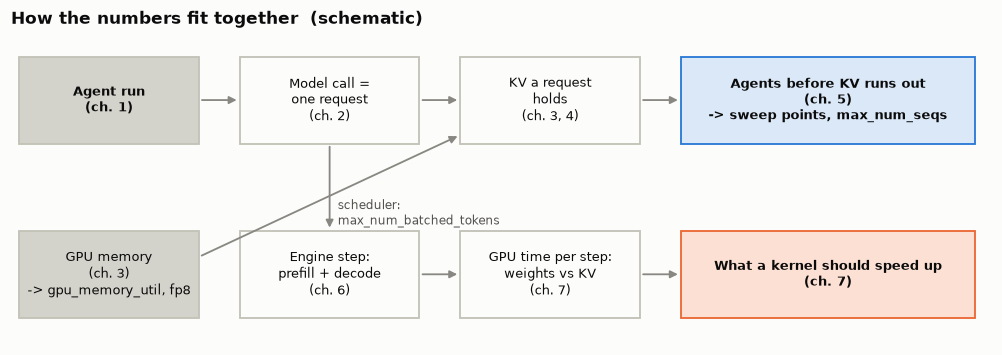

In [9]:
fig, ax = plt.subplots(figsize=(11.5, 3.6))
ax.set_xlim(0, 12); ax.set_ylim(1.1, 4.6); ax.axis("off")
box(ax, 0.1, 3.4, 2.2, 1.0, "Agent run\n(ch. 1)", fc=G3, bold=True)
box(ax, 2.8, 3.4, 2.2, 1.0, "Model call =\none request\n(ch. 2)")
box(ax, 5.5, 3.4, 2.2, 1.0, "KV a request\nholds\n(ch. 3, 4)")
box(ax, 8.2, 3.4, 3.6, 1.0, "Agents before KV runs out\n(ch. 5)\n-> sweep points, max_num_seqs", fc="#dbe8f8", ec=BLUE, bold=True)
box(ax, 2.8, 1.4, 2.2, 1.0, "Engine step:\nprefill + decode\n(ch. 6)")
box(ax, 5.5, 1.4, 2.2, 1.0, "GPU time per step:\nweights vs KV\n(ch. 7)")
box(ax, 8.2, 1.4, 3.6, 1.0, "What a kernel should speed up\n(ch. 7)", fc="#fbe0d3", ec=ORANGE, bold=True)
box(ax, 0.1, 1.4, 2.2, 1.0, "GPU memory\n(ch. 3)\n-> gpu_memory_util, fp8", fc=G3)
for x0, x1, y in [(2.3, 2.8, 3.9), (5.0, 5.5, 3.9), (7.7, 8.2, 3.9), (5.0, 5.5, 1.9), (7.7, 8.2, 1.9)]:
    arrow(ax, x0, y, x1, y)
arrow(ax, 3.9, 3.4, 3.9, 2.4)
arrow(ax, 2.3, 2.1, 5.5, 3.5)
ax.text(4.0, 2.6, "scheduler:\nmax_num_batched_tokens", fontsize=8, color=INK2, va="center")
title(ax, "How the numbers fit together  (schematic)")
plt.show()

## Chapter 1: what does one agent run actually do?

**The question.** The server never sees "an agent". It sees a stream of chat requests. To know how much load an agent puts
on the server, you first need to see what one run does over time.

An agent run is a loop:

1. **Model call.** The model reads the whole conversation so far (the *prompt*), thinks, and either answers or asks for a search.
2. **Tool call.** If it asked for a search, your code runs it (cache or Brave) and appends the result to the conversation.
3. Go to 1, with a **longer** prompt: everything before, plus the model's last turn, plus the search result.

Two things follow, and the rest of the notebook builds on both:

- The server only works on this agent **during model calls**. During a tool call, the agent is idle from the server's point of view.
- **Prompts grow** with every step, because search results pile up. Later calls are much bigger than the first.

The chart below is one real run from your traces: of the runs that searched at least once, the one with the median duration.

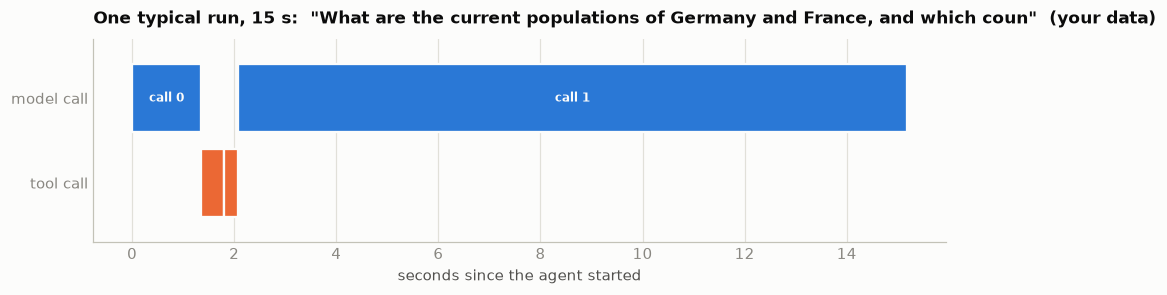

In [13]:
def lanes(ax, a):
    ax.broken_barh([(m["t"], m["len"]) for m in a["model"]], (0.6, 0.8), facecolors=BLUE, edgecolor=SURFACE, linewidth=1.5)
    if a["tools"]:
        ax.broken_barh([(t["t"], t["len"]) for t in a["tools"]], (-0.4, 0.8), facecolors=ORANGE, edgecolor=SURFACE, linewidth=1.5)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["tool call", "model call"]); ax.set_ylim(-0.7, 1.7); ax.tick_params(length=0)
    for i, m in enumerate(a["model"]):
        ax.text(m["t"] + m["len"] / 2, 1.0, f"call {i}", ha="center", va="center", fontsize=8, color=SURFACE, fontweight="bold")

if AGENTS:
    searched = [a for a in AGENTS if a["tools"]] or AGENTS        # a run with no search would hide half the story
    TYPICAL = sorted(searched, key=lambda a: a["dur"])[len(searched) // 2]
    HEAVIEST = max(AGENTS, key=lambda a: max((m["prompt"] + m["out"] for m in a["model"]), default=0))
    fig, ax = plt.subplots(figsize=(10, 2.4))
    lanes(ax, TYPICAL)
    ax.set_xlabel("seconds since the agent started"); ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    title(ax, f"One typical run, {TYPICAL['dur']:.0f} s:  \"{TYPICAL['question'][:70]}\"  (your data)")
    plt.show()

Now look at **how big each model call's prompt is**, call by call. Each bar is split into what was already there at the
previous call (gray), what was added since: the model's previous turn plus the search results (blue), and what the model
generated in this call (orange).

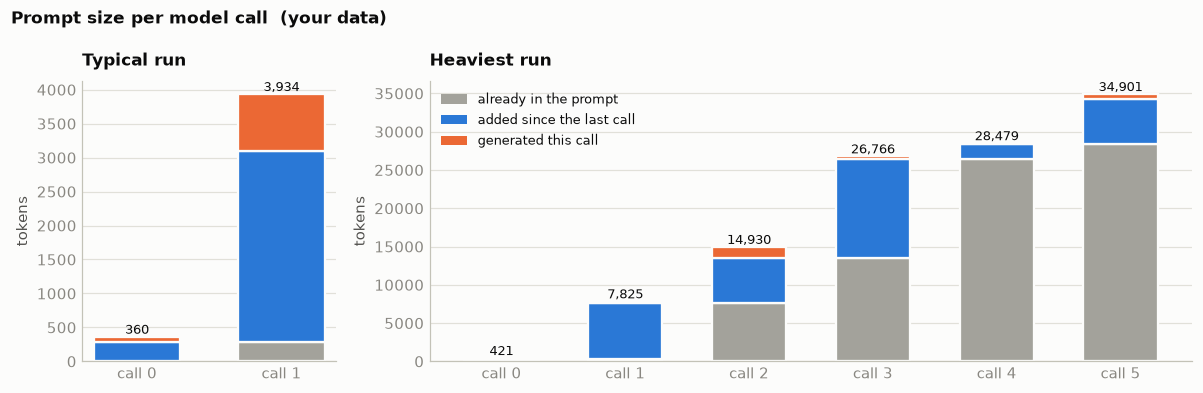

In [14]:
def growth_bars(ax, a, name):
    prev = 0
    for i, m in enumerate(a["model"]):
        carried, new = (prev, m["prompt"] - prev) if i else (0, m["prompt"])
        ax.bar(i, carried, color=G2, edgecolor=SURFACE, linewidth=1.5, width=0.6)
        ax.bar(i, new, bottom=carried, color=BLUE, edgecolor=SURFACE, linewidth=1.5, width=0.6)
        ax.bar(i, m["out"], bottom=m["prompt"], color=ORANGE, edgecolor=SURFACE, linewidth=1.5, width=0.6)
        ax.text(i, m["prompt"] + m["out"], f"{m['prompt'] + m['out']:,}", ha="center", va="bottom", fontsize=8.5)
        prev = m["prompt"]
    ax.set_xticks(range(len(a["model"]))); ax.set_xticklabels([f"call {i}" for i in range(len(a["model"]))])
    ax.set_ylabel("tokens"); style(ax); title(ax, name)

if AGENTS:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [len(TYPICAL["model"]), len(HEAVIEST["model"])]})
    growth_bars(axes[0], TYPICAL, "Typical run")
    growth_bars(axes[1], HEAVIEST, "Heaviest run")
    axes[1].legend(handles=[Patch(fc=G2, label="already in the prompt"), Patch(fc=BLUE, label="added since the last call"),
                            Patch(fc=ORANGE, label="generated this call")], frameon=False, fontsize=8.5, loc="upper left")
    fig.suptitle("Prompt size per model call  (your data)", x=0.01, ha="left", fontweight="bold", fontsize=11)
    plt.tight_layout(); plt.show()

**Where these numbers live.** Every model call and tool call is one line in `tracing/traces_<tag>.jsonl`, written by
`tracing/tracer.py`. Here are the raw events for the typical run (long fields trimmed):

In [15]:
if AGENTS:
    keep = {"model": ["type", "call_index", "prompt_tokens", "completion_tokens", "latency_ms", "ttft_any_ms", "decode_ms", "finish_reason"],
            "tool": ["type", "step", "latency_ms", "result_chars", "cache_hit"],
            "run_start": ["type"], "run_end": ["type", "status", "duration_ms", "model_calls", "tool_calls"]}
    for e in TYPICAL["events"]:
        fields = {k: (round(e[k], 1) if isinstance(e[k], float) else e[k]) for k in keep.get(e["type"], ["type"]) if k in e}
        print(json.dumps(fields))

{"type": "run_start"}
{"type": "model", "call_index": 0, "prompt_tokens": 284, "completion_tokens": 76, "latency_ms": 1349.8, "ttft_any_ms": 219.3, "decode_ms": 1130.5, "finish_reason": "tool_calls"}
{"type": "tool", "step": 0, "latency_ms": 451.0, "result_chars": 5086, "cache_hit": true}
{"type": "tool", "step": 0, "latency_ms": 267.2, "result_chars": 4475, "cache_hit": true}
{"type": "model", "call_index": 1, "prompt_tokens": 3100, "completion_tokens": 834, "latency_ms": 13113.0, "ttft_any_ms": 405.4, "decode_ms": 12707.6, "finish_reason": "stop"}
{"type": "run_end", "status": "ok", "duration_ms": 15182.6, "model_calls": 2, "tool_calls": 2}


**Across all your runs.** The typical run is one sample. Here is the spread: how many model calls and searches the runs
made. The agent's behaviour varies a lot from question to question, and that spread is what the server has to absorb.

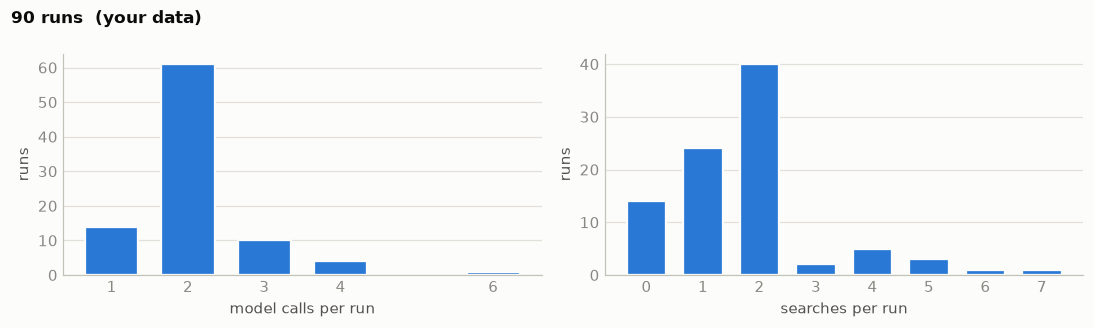

In [16]:
if AGENTS:
    calls = [len(a["model"]) for a in AGENTS]; searches = [len(a["tools"]) for a in AGENTS]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.0))
    for ax, data, name in [(axes[0], calls, "model calls per run"), (axes[1], searches, "searches per run")]:
        vals, counts = np.unique(data, return_counts=True)
        ax.bar(vals, counts, color=BLUE, edgecolor=SURFACE, linewidth=1.5, width=0.7)
        ax.set_xticks(vals); ax.set_xlabel(name); ax.set_ylabel("runs"); style(ax)
    fig.suptitle(f"{len(AGENTS)} runs  (your data)", x=0.01, ha="left", fontweight="bold", fontsize=11)
    plt.tight_layout(); plt.show()

**Try it.** From the typical run's raw events above: what fraction of the run's time was spent **inside model calls**?
Add up the model calls' `latency_ms` and divide by the run's `duration_ms`. Then run the next cell.

This fraction is the most important single number for turning agents into server load. Chapter 5 uses it.

In [17]:
if AGENTS:
    share_one = sum(m["len"] for m in TYPICAL["model"]) / TYPICAL["dur"]
    share_all = sum(m["len"] for m in CALLS) / sum(a["dur"] for a in AGENTS)
    MODEL_SHARE = share_all
    print(f"typical run: {100 * share_one:.0f}% of its time inside model calls")
    print(f"all runs:    {100 * share_all:.0f}%   (this is W8 in `python -m Benchmarking.analyze --worksheet`)")
    print(f"model calls per run: {len(CALLS) / len(AGENTS):.2f}   (W17)")

typical run: 95% of its time inside model calls
all runs:    92%   (this is W8 in `python -m Benchmarking.analyze --worksheet`)
model calls per run: 2.09   (W17)


**Why it matters next.** If agents spend most of their time inside model calls, then **agents ≈ requests in flight**,
and the server sees almost one request per agent. The tool time is a small gap between calls. Keep this in mind for
Chapter 5.

## Chapter 2: what happens inside one model call?

**The question.** One model call is one request to vLLM. What does the server do with it, and which part takes the time?

A request goes through three phases:

- **Queue.** It waits until the scheduler admits it. At concurrency 1 this is about zero.
- **Prefill.** The model processes **all the prompt tokens at once**. That's big matrix multiplications over thousands of
  tokens: lots of arithmetic per byte read, so prefill is **compute-bound**. It ends when the first new token comes out:
  that moment is the **time to first token (TTFT)**.
- **Decode.** The model generates **one token per step**. Every step has to read *all* the model's weights and this request's
  KV cache from GPU memory, just to produce one token. Little arithmetic per byte, so decode is **memory-bound**. The time between two tokens is the
  **inter-token latency (ITL)**. The reasoning tokens are decode too, before the visible answer starts.

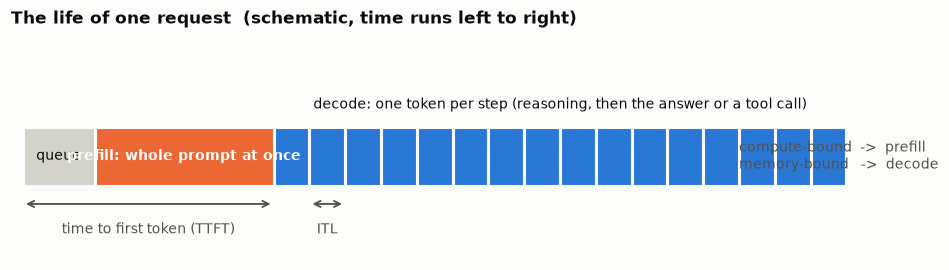

In [26]:
fig, ax = plt.subplots(figsize=(10.5, 2.6))
ax.set_xlim(0, 15); ax.set_ylim(0, 3); ax.axis("off")
ax.add_patch(Rectangle((0.2, 1.0), 1.2, 0.8, fc=G3, ec=SURFACE, lw=2)); ax.text(0.8, 1.4, "queue", ha="center", va="center", fontsize=9)
ax.add_patch(Rectangle((1.4, 1.0), 3.0, 0.8, fc=ORANGE, ec=SURFACE, lw=2)); ax.text(2.9, 1.4, "prefill: whole prompt at once", ha="center", va="center", fontsize=9, color=SURFACE, fontweight="bold")
for i in range(16):
    ax.add_patch(Rectangle((4.4 + i * 0.6, 1.0), 0.6, 0.8, fc=BLUE, ec=SURFACE, lw=2))
ax.text(9.2, 2.05, "decode: one token per step (reasoning, then the answer or a tool call)", ha="center", fontsize=9)
ax.annotate("", xy=(4.4, 0.75), xytext=(0.2, 0.75), arrowprops=dict(arrowstyle="<->", color=INK2, lw=1.2))
ax.text(2.3, 0.35, "time to first token (TTFT)", ha="center", fontsize=9, color=INK2)
ax.annotate("", xy=(5.6, 0.75), xytext=(5.0, 0.75), arrowprops=dict(arrowstyle="<->", color=INK2, lw=1.2))
ax.text(5.3, 0.35, "ITL", ha="center", fontsize=9, color=INK2)
ax.text(12.2, 1.4, "compute-bound  ->  prefill\nmemory-bound   ->  decode", fontsize=9, va="center", color=INK2)
title(ax, "The life of one request  (schematic, time runs left to right)")
plt.show()

**Prefill in your data.** If prefill speed were constant, TTFT would grow in a straight line with the prompt length. Each
dot below is one model call. Calls whose prompt was mostly already in the server's **prefix cache** (Chapter 4) skip most
of the work and sit below the line.

The dashed line is the median `prompt tokens / TTFT` for prompts over 2,000 tokens. It's a client-side number: TTFT here also
includes the network round trip and any time before the server starts, so it comes out a little lower than the server's own
prefill speed a few cells below.

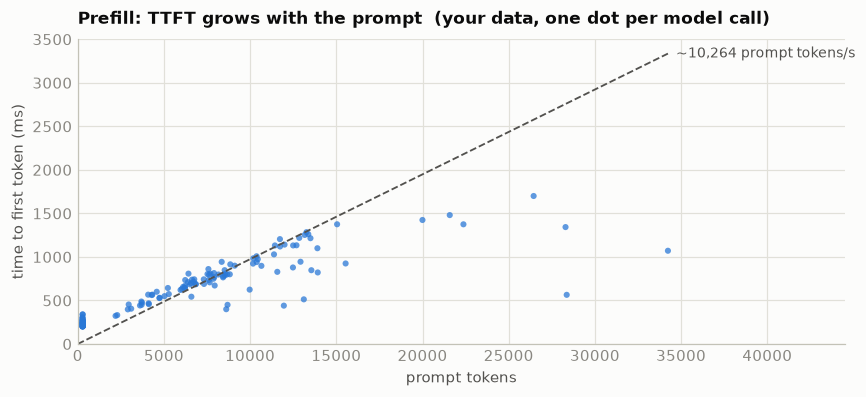

In [27]:
if CALLS:
    x = np.array([m["prompt"] for m in CALLS]); y = np.array([m["ttft"] for m in CALLS])
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.scatter(x, y, s=16, color=BLUE, alpha=0.75, edgecolor="none")
    big = x > 2000
    if big.sum() >= 3:
        rate = np.median(x[big] / (y[big] / 1000))
        xs = np.linspace(0, x.max(), 50)
        ax.plot(xs, xs / rate * 1000, color=INK2, ls="--", lw=1.2)
        ax.text(xs[-1], xs[-1] / rate * 1000, f"  ~{rate:,.0f} prompt tokens/s", va="center", fontsize=9, color=INK2)
    ax.set_xlabel("prompt tokens"); ax.set_ylabel("time to first token (ms)"); style(ax, "both")
    ax.set_xlim(0, x.max() * 1.3); ax.set_ylim(bottom=0)
    title(ax, "Prefill: TTFT grows with the prompt  (your data, one dot per model call)")
    plt.show()

**Decode in your data.** Per call, decode speed is `completion tokens / decode time`. At concurrency 1 the GPU serves one
sequence at a time, so this is the fastest a single request can generate.

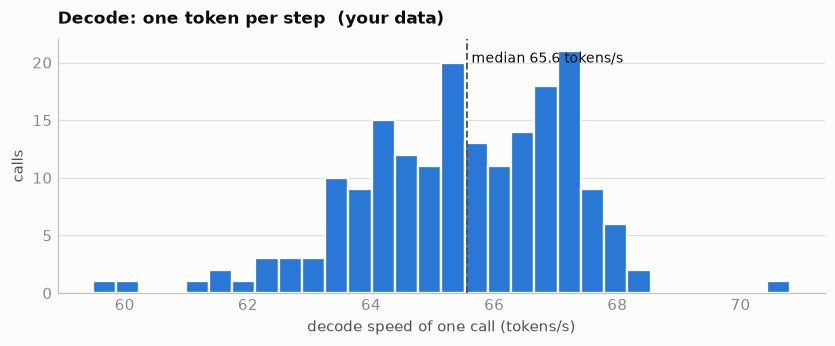

In [28]:
dec = [m["out"] / (m["decode_ms"] / 1000) for m in CALLS if m["out"] >= 50 and m["decode_ms"]]
if dec:
    fig, ax = plt.subplots(figsize=(9, 3.0))
    ax.hist(dec, bins=30, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
    ax.axvline(np.median(dec), color=INK2, ls="--", lw=1.2)
    ax.text(np.median(dec), ax.get_ylim()[1] * 0.95, f" median {np.median(dec):.1f} tokens/s", va="top", fontsize=9)
    ax.set_xlabel("decode speed of one call (tokens/s)"); ax.set_ylabel("calls"); style(ax)
    title(ax, "Decode: one token per step  (your data)")
    plt.show()

**Where the server's numbers live.** vLLM keeps running **histograms** of these quantities in its `/metrics` endpoint, and
your scraper saves a copy every second to `tracing/vllm_metrics.jsonl`. A histogram is stored as a running `_sum` and `_count`.
The mean over a window is

```
mean over the window  =  (sum at the end - sum at the start) / (count at the end - count at the start)
```

Here are the raw lines for inter-token latency at the start and end of your first pass, and the mean they give:

In [29]:
if FIRST_WINDOW:
    s0, s1 = FIRST_WINDOW
    for name in ["vllm:inter_token_latency_seconds_sum", "vllm:inter_token_latency_seconds_count"]:
        k = next(k for k in s0["m"] if k.split("{")[0] == name)
        print(f"{name:42}  start {s0['m'][k]:>14,.3f}   end {s1['m'][k]:>14,.3f}")
    ds = delta(s0["m"], s1["m"], "vllm:inter_token_latency_seconds_sum"); dc = delta(s0["m"], s1["m"], "vllm:inter_token_latency_seconds_count")
    print(f"\nmean ITL in this window = {ds:,.3f} s / {dc:,.0f} tokens = {1000 * ds / dc:.2f} ms per token  ->  {dc / ds:.1f} tokens/s")
else:
    print("no server metrics in these runs' windows")

vllm:inter_token_latency_seconds_sum        start          1.176   end        650.193
vllm:inter_token_latency_seconds_count      start         78.000   end     42,144.000

mean ITL in this window = 649.017 s / 42,066 tokens = 15.43 ms per token  ->  64.8 tokens/s


In [30]:
if SRV:
    rows = [
        ("time to first token, mean (ms)", 1000 * hmean("vllm:time_to_first_token_seconds"), ""),
        ("queue time, mean (ms)", 1000 * hmean("vllm:request_queue_time_seconds"), "about 0 at concurrency 1"),
        ("prompt tokens actually computed per request", hmean("vllm:request_prefill_kv_computed_tokens"), "W14: after prefix-cache hits"),
        ("prefill speed (tokens/s)", SRV["vllm:request_prefill_kv_computed_tokens_sum"] / SRV["vllm:request_prefill_time_seconds_sum"], "W15: computed tokens / prefill time"),
        ("inter-token latency (ms)", 1000 * hmean("vllm:inter_token_latency_seconds"), "W16"),
        ("tokens per engine step, mean", hmean("vllm:iteration_tokens_total"), "Chapter 6"),
    ]
    print("The server's view of your passes")
    for name, v, note in rows:
        print(f"  {name:46}{v:>10,.1f}   {note}")

The server's view of your passes
  time to first token, mean (ms)                     288.0   
  queue time, mean (ms)                                0.0   about 0 at concurrency 1
  prompt tokens actually computed per request      3,626.0   W14: after prefix-cache hits
  prefill speed (tokens/s)                        13,564.3   W15: computed tokens / prefill time
  inter-token latency (ms)                            15.5   W16
  tokens per engine step, mean                         9.3   Chapter 6


**Where does a model call's time go?** Add up, across all calls, the time before the first token (queue + prefill) and the
time spent decoding:

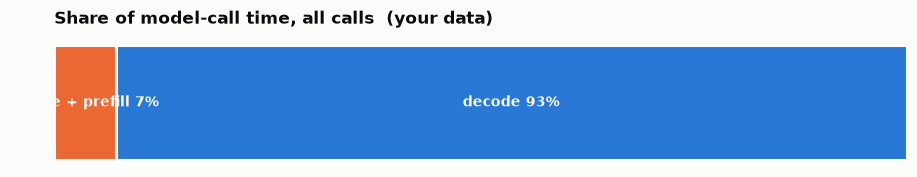

In [31]:
if CALLS:
    t_pre = sum(m["ttft"] for m in CALLS if m["ttft"] is not None) / 1000
    t_dec = sum(m["decode_ms"] for m in CALLS if m["decode_ms"] is not None) / 1000
    tot = t_pre + t_dec
    fig, ax = plt.subplots(figsize=(10, 1.5))
    ax.barh(0, t_pre / tot, color=ORANGE, edgecolor=SURFACE, linewidth=2, height=0.6)
    ax.barh(0, t_dec / tot, left=t_pre / tot, color=BLUE, edgecolor=SURFACE, linewidth=2, height=0.6)
    ax.text(t_pre / tot / 2, 0, f"queue + prefill {100 * t_pre / tot:.0f}%", ha="center", va="center", color=SURFACE, fontsize=9, fontweight="bold")
    ax.text(t_pre / tot + t_dec / tot / 2, 0, f"decode {100 * t_dec / tot:.0f}%", ha="center", va="center", color=SURFACE, fontsize=9, fontweight="bold")
    ax.set_xlim(0, 1); ax.axis("off")
    title(ax, "Share of model-call time, all calls  (your data)")
    plt.show()

**Why it matters next.** At concurrency 1, almost all the model time is **decode**, which is memory-bound. That changes
under load: with many agents, the GPU decodes many sequences in the same step, so it reads the weights once for all of them
(Chapter 7). Prefill becomes more important too, because every call re-sends a long prompt.

For the sweep, watch **TTFT** (prefill and queueing) and **ITL** (decode) separately. They respond to different knobs.

## Chapter 3: what is the KV cache, and how big is it?

**The question.** Decode reads "this request's KV cache" every step. What is it, and how many bytes does each token cost?

To produce the next token, attention needs a **key** and a **value** vector for **every token before it**, in **every layer**.
Recomputing them each step would be wasteful, so vLLM computes each token's K and V once and keeps them in GPU memory: the
**KV cache**. Its size per token depends only on the model's shape:

```
KV bytes per token  =  2 (K and V)  x  layers  x  KV heads  x  head size  x  bytes per number
```

The "KV heads" are not the same as the attention heads. With **grouped-query attention**, several query heads share one KV
head, which shrinks the cache.

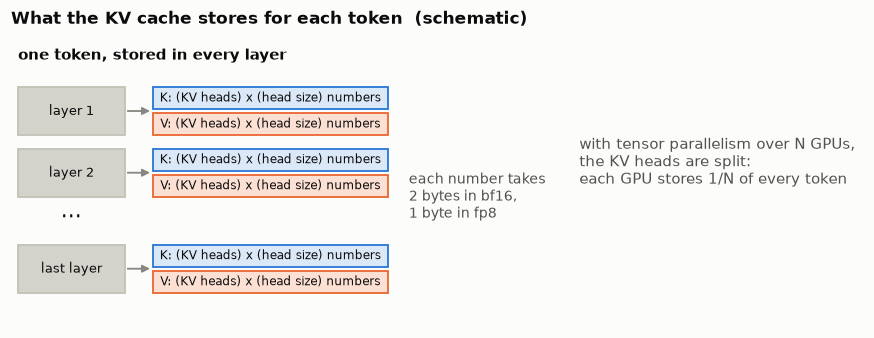

In [32]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.set_xlim(0, 12); ax.set_ylim(0, 4.2); ax.axis("off")
ax.text(0.1, 3.9, "one token, stored in every layer", fontsize=10, fontweight="bold")
for i, y in enumerate([2.8, 1.9]):
    box(ax, 0.1, y, 1.5, 0.7, f"layer {i + 1}", fc=G3)
ax.text(0.85, 1.6, "...", ha="center", fontsize=14); box(ax, 0.1, 0.5, 1.5, 0.7, "last layer", fc=G3)
for y in (2.8, 1.9, 0.5):
    box(ax, 2.0, y + 0.38, 3.3, 0.32, "K: (KV heads) x (head size) numbers", fc="#dbe8f8", ec=BLUE, fs=8)
    box(ax, 2.0, y, 3.3, 0.32, "V: (KV heads) x (head size) numbers", fc="#fbe0d3", ec=ORANGE, fs=8)
    arrow(ax, 1.6, y + 0.35, 2.0, y + 0.35)
ax.text(5.6, 1.9, "each number takes\n2 bytes in bf16,\n1 byte in fp8", fontsize=9, color=INK2, va="center")
ax.text(8.0, 2.4, "with tensor parallelism over N GPUs,\nthe KV heads are split:\neach GPU stores 1/N of every token", fontsize=9.5, va="center", color=INK2)
title(ax, "What the KV cache stores for each token  (schematic)")
plt.show()

**Where the model's shape lives.** It's in the model's `config.json` on Hugging Face. The next cell fetches it and prints the
fields that matter.

In [33]:
try:
    CFG = json.load(urllib.request.urlopen(f"https://huggingface.co/{MODEL}/raw/main/config.json", timeout=20))
except Exception as e:
    CFG = None
    print("could not fetch config.json:", e, "\nopen https://huggingface.co/" + MODEL + " and read the fields by hand")
if CFG:
    for k in ["num_hidden_layers", "num_attention_heads", "num_key_value_heads", "head_dim", "hidden_size",
              "intermediate_size", "vocab_size", "tie_word_embeddings", "dtype"]:
        print(f"  {k:24} {CFG.get(k)}")
    sys.path.insert(0, str(ROOT)); import server_config
    TP = server_config.N_GPU
    print(f"\n  tensor-parallel size (N_GPU in server_config.py): {TP}")

  num_hidden_layers        64
  num_attention_heads      64
  num_key_value_heads      8
  head_dim                 128
  hidden_size              5120
  intermediate_size        26624
  vocab_size               250624
  tie_word_embeddings      False
  dtype                    bfloat16

  tensor-parallel size (N_GPU in server_config.py): 2


**Try it.** Using the fields above, how many **bytes per token** does the KV cache need across all GPUs, in bf16 (2 bytes
per number)? How many per GPU? Then run the next cell.

In [34]:
if CFG:
    L, KVH, HD = CFG["num_hidden_layers"], CFG["num_key_value_heads"], CFG["head_dim"]
    KV_BYTES = 2 * L * KVH * HD * 2
    print(f"KV bytes per token = 2 x {L} layers x {KVH} KV heads x {HD} head size x 2 bytes = {KV_BYTES:,} bytes ({KV_BYTES / 2**20:.3f} MiB)")
    print(f"per GPU (split over {TP}):  {KV_BYTES / TP:,.0f} bytes")
    QH = CFG["num_attention_heads"]
    print(f"\nwithout grouped-query attention ({QH} KV heads instead of {KVH}) it would be {QH // KVH}x bigger: {KV_BYTES * QH // KVH / 2**20:.2f} MiB per token")

KV bytes per token = 2 x 64 layers x 8 KV heads x 128 head size x 2 bytes = 262,144 bytes (0.250 MiB)
per GPU (split over 2):  131,072 bytes

without grouped-query attention (64 KV heads instead of 8) it would be 8x bigger: 2.00 MiB per token


**How many tokens fit.** At startup, vLLM loads the weights, measures its own working memory, and gives the rest of its
memory budget to the KV cache. It reports the result as a **number of tokens**, which your scraper records. Here is the raw label from
`/metrics`:

In [35]:
if SRV_CFG:
    for key in ["kv_cache_size_tokens", "num_gpu_blocks", "block_size", "gpu_memory_utilization", "cache_dtype", "enable_prefix_caching"]:
        print(f"  {key:24} {label(SRV_CFG, 'vllm:cache_config_info', key)}")
    W1 = float(label(SRV_CFG, "vllm:cache_config_info", "kv_cache_size_tokens"))
    BLOCK = int(label(SRV_CFG, "vllm:cache_config_info", "block_size"))
    if CFG:
        print(f"\n{W1:,.0f} tokens x {KV_BYTES:,} bytes = {W1 * KV_BYTES / 2**30:.1f} GiB of KV cache in total, {W1 * KV_BYTES / 2**30 / TP:.1f} GiB per GPU")
        print(f"it fits {W1 / server_config.MAX_MODEL_LEN:.2f} requests of the maximum length ({server_config.MAX_MODEL_LEN:,} tokens)")
else:
    W1 = BLOCK = None
    print("no server metrics: the same number is in the startup log as 'GPU KV cache size: N tokens'")

  kv_cache_size_tokens     299952
  num_gpu_blocks           18747
  block_size               16
  gpu_memory_utilization   0.9
  cache_dtype              auto
  enable_prefix_caching    True

299,952 tokens x 262,144 bytes = 73.2 GiB of KV cache in total, 36.6 GiB per GPU
it fits 4.69 requests of the maximum length (64,000 tokens)


**Where the memory goes.** The server's startup log says how it split each GPU's memory. Those lines are not saved
anywhere unless you copy them, so either point `BOOT_LOG` (setup cell) at a saved copy, or fill in `BOOT` below by hand
from these lines:

- `Free memory on device (X/Y GiB)`: Y is the GPU's total, X was free at startup
- `Actual usage is A GiB for consumed memory (weights + non-torch), B GiB for peak activation, and C GiB for CUDAGraph memory`
- `Available KV cache memory: D GiB`

Everything is **per GPU**.

free memory on device 77.5/79.17 gb
Actual usage is 32.74 GB GiB for consumed memory 1.9 GiB for peak activation, and 0.25 GiB for CUDAGraph memor
current kv cache memory in usage is 36.62 gb


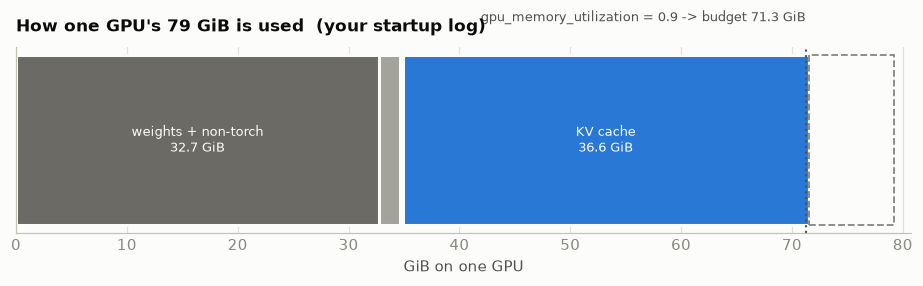

budget - weights - activations - CUDA graphs = 36.36 GiB;  the log says KV = 36.62 GiB


In [36]:
BOOT = dict(total=79.17, free=77.5, weights=32.74, activation=1.9, cudagraph=0.25, kv=36.62)    # GiB per GPU

if BOOT_LOG and Path(BOOT_LOG).exists():
    text = Path(BOOT_LOG).read_text()
    if m := re.search(r"Free memory on device \(([\d.]+)/([\d.]+) GiB\)", text):
        BOOT["free"], BOOT["total"] = float(m.group(1)), float(m.group(2))
    if m := re.search(r"([\d.]+) GiB for consumed memory \(weights \+ non-torch\), ([\d.]+) GiB for peak activation, and ([\d.]+) GiB for CUDAGraph", text):
        BOOT["weights"], BOOT["activation"], BOOT["cudagraph"] = map(float, m.groups())
    if m := re.search(r"Available KV cache memory: ([\d.]+) GiB", text):
        BOOT["kv"] = float(m.group(1))

u = server_config.GPU_MEM_UTIL if CFG else None
if None not in BOOT.values() and u:
    budget = u * BOOT["total"]
    fig, ax = plt.subplots(figsize=(10.5, 2.2))
    left = 0
    for w, c, name in [(BOOT["weights"], G1, "weights + non-torch"), (BOOT["activation"], G2, "activations"),
                       (BOOT["cudagraph"], G3, "CUDA graphs"), (BOOT["kv"], BLUE, "KV cache")]:
        ax.barh(0, w, left=left, color=c, edgecolor=SURFACE, linewidth=2, height=0.6)
        if w > 3:
            ax.text(left + w / 2, 0, f"{name}\n{w:.1f} GiB", ha="center", va="center", fontsize=8.5, color=SURFACE if c in (G1, BLUE) else INK)
        left += w
    ax.barh(0, BOOT["total"] - left, left=left, color=SURFACE, edgecolor=MUTED, linestyle="--", linewidth=1.2, height=0.6)
    ax.axvline(budget, color=INK2, ls=":", lw=1.4)
    ax.text(budget, 0.42, f"gpu_memory_utilization = {u} -> budget {budget:.1f} GiB", ha="right", fontsize=8.5, color=INK2)
    ax.set_xlim(0, BOOT["total"] * 1.02); ax.set_yticks([]); ax.set_xlabel("GiB on one GPU"); style(ax, "x")
    title(ax, f"How one GPU's {BOOT['total']:.0f} GiB is used  (your startup log)")
    plt.show()
    print(f"budget - weights - activations - CUDA graphs = {budget - BOOT['weights'] - BOOT['activation'] - BOOT['cudagraph']:.2f} GiB;  the log says KV = {BOOT['kv']} GiB")
else:
    print("fill in BOOT (or set BOOT_LOG) to draw this chart:", [k for k, v in BOOT.items() if v is None])

**Why it matters next: two knobs act directly on this.**

- **`gpu_memory_utilization`** is the fraction of the GPU vLLM may use. Everything above the weights and working memory goes
  to KV, so each extra 0.01 adds about 1% of the GPU's memory to the cache. The rest is **headroom** against running out of memory.
  It can't exceed what was free at startup.
- **`kv_cache_dtype = fp8`** stores each number in 1 byte instead of 2, so the same memory holds **about twice the tokens**.
  It also halves the bytes decode has to read per token (Chapter 7). The cost is some accuracy, which you'd have to check on the answers.

```
KV tokens  ~  (u x total  -  weights  -  activations  -  CUDA graphs)  x  N_GPU  /  (KV bytes per token)
```

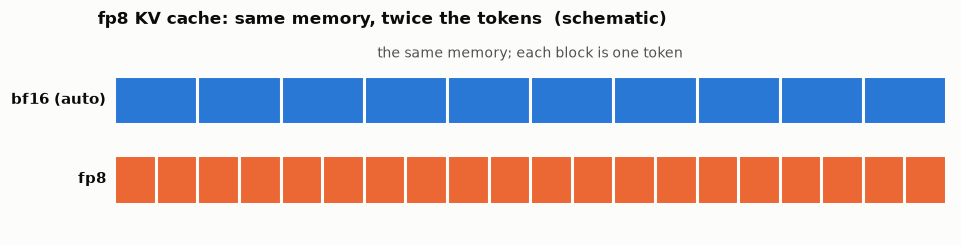

In [37]:
fig, ax = plt.subplots(figsize=(10, 2.3))
ax.set_xlim(0, 20.5); ax.set_ylim(0, 3.2); ax.axis("off")
for y, n, lab in [(1.8, 10, "bf16 (auto)"), (0.5, 20, "fp8")]:
    w = 20 / n
    for k in range(n):
        ax.add_patch(Rectangle((0.4 + k * w, y), w, 0.8, fc=BLUE if n == 10 else ORANGE, ec=SURFACE, lw=2))
    ax.text(0.2, y + 0.4, lab, ha="right", va="center", fontsize=9.5, fontweight="bold")
ax.text(10.4, 2.9, "the same memory; each block is one token", ha="center", fontsize=9, color=INK2)
title(ax, "fp8 KV cache: same memory, twice the tokens  (schematic)")
plt.show()

## Chapter 4: how much KV cache does a request hold?

**The question.** Chapter 3 gave the cache size in tokens. To know how many requests fit, you need to know how many tokens a
request holds, and for how long.

A request's KV grows while it runs: first the whole prompt (after prefill), then one more token per decode step. When the
call ends, vLLM frees it. During a tool call, the agent holds **nothing**. Here is the KV held by the typical run and by the heaviest run:

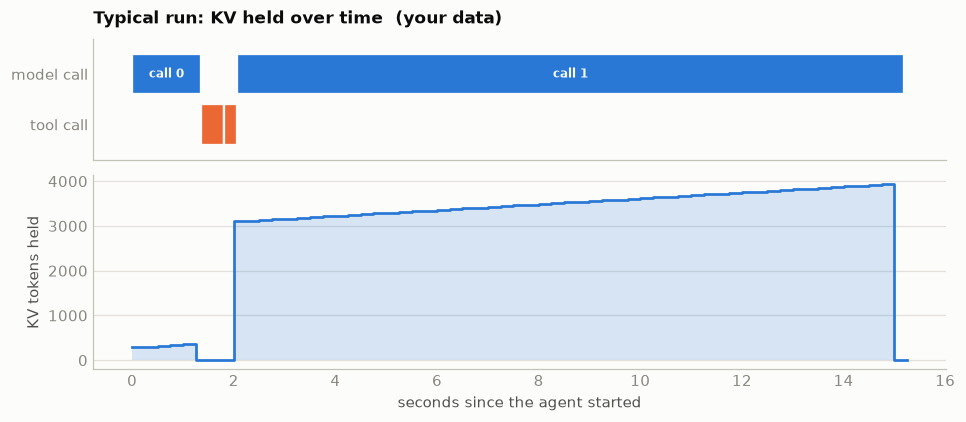

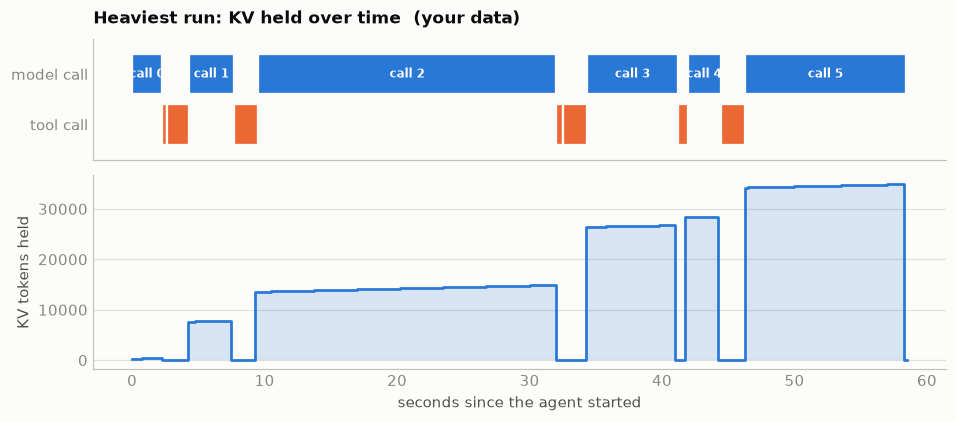

In [38]:
DT = 0.25
def occupancy(a):
    """KV tokens one run holds over time (sampled every DT seconds)."""
    n = int(math.ceil(a["dur"] / DT)) + 1
    occ = np.zeros(n)
    for m in a["model"]:
        i0 = int(m["t"] / DT); i1 = min(max(int((m["t"] + m["len"]) / DT), i0 + 1), n)
        if i1 > i0:
            occ[i0:i1] = np.linspace(m["prompt"], m["prompt"] + m["out"], i1 - i0)
    return occ

if AGENTS:
    for a, name in [(TYPICAL, "Typical run"), (HEAVIEST, "Heaviest run")]:
        fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 3.9), sharex=True, gridspec_kw={"height_ratios": [1, 1.6], "hspace": 0.1})
        lanes(a1, a)
        occ = occupancy(a); t = np.arange(len(occ)) * DT
        a2.fill_between(t, occ, step="post", color=BLUE, alpha=0.18, linewidth=0); a2.step(t, occ, where="post", color=BLUE, lw=1.8)
        a2.set_ylabel("KV tokens held"); a2.set_xlabel("seconds since the agent started"); style(a2)
        title(a1, f"{name}: KV held over time  (your data)")
        plt.show()

Three numbers summarise a request's size. Each answers a different question:

- **Mean resident context** (`W4`): averaged over the time requests are running. Use it to answer "how many fit, typically?"
- **p90 at the end of a call** (`W6`): 1 call in 10 is bigger than this. Use it to answer "how many fit when the load is heavy?"
- **Max** (`W7`): the biggest call you saw. Use it to answer "can one monster request still fit?"

The histogram shows why the choice matters: most calls are small, but a long tail of calls carries several search results.

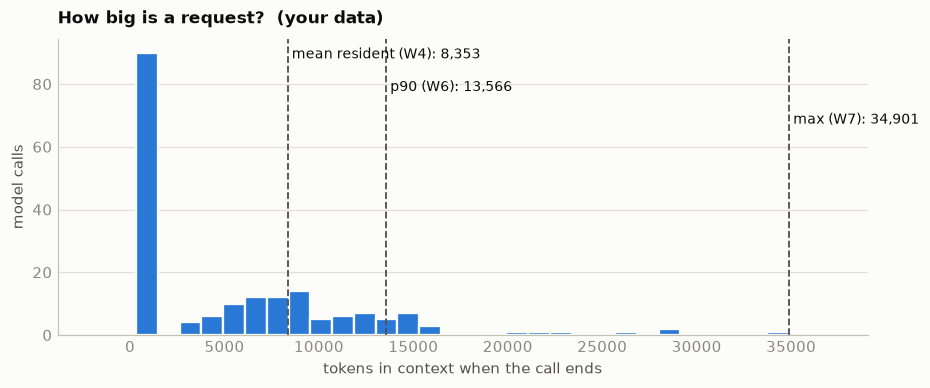

In [39]:
if CALLS:
    ends = np.array([m["prompt"] + m["out"] for m in CALLS])
    w = np.array([m["len"] for m in CALLS]); resident = np.array([m["prompt"] + m["out"] / 2 for m in CALLS])
    R = {"mean resident (W4)": float((w * resident).sum() / w.sum()), "p90 (W6)": pct(ends, 90), "max (W7)": float(ends.max())}
    fig, ax = plt.subplots(figsize=(9.5, 3.5))
    ax.hist(ends, bins=30, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
    top = ax.get_ylim()[1]
    for i, (name, v) in enumerate(R.items()):
        ax.axvline(v, color=INK2, ls="--", lw=1.2); ax.text(v, top * (0.97 - 0.11 * i), f" {name}: {v:,.0f}", va="top", fontsize=9)
    ax.margins(x=0.12); ax.set_xlabel("tokens in context when the call ends"); ax.set_ylabel("model calls"); style(ax)
    title(ax, "How big is a request?  (your data)")
    plt.show()

**The prefix cache: why real usage is lower.** Every one of your requests starts with the same system prompt and tool
definitions, and every call of one agent starts with the whole previous conversation. vLLM notices when a new request
starts with blocks it already has in memory and **reuses** them instead of recomputing and storing them again.

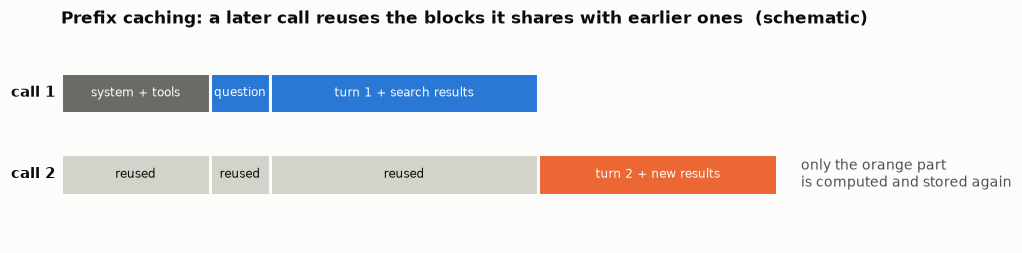

your passes: 28% of prompt tokens were served from the prefix cache (267,088 reused vs 686,508 computed)


In [40]:
fig, ax = plt.subplots(figsize=(10.5, 2.4))
ax.set_xlim(0, 15); ax.set_ylim(0, 3); ax.axis("off")
def blocks(y, spec, lab):
    ax.text(-0.1, y + 0.3, lab, ha="right", va="center", fontsize=9.5, fontweight="bold")
    x = 0
    for w, c, t in spec:
        ax.add_patch(Rectangle((x, y), w, 0.6, fc=c, ec=SURFACE, lw=2))
        if t: ax.text(x + w / 2, y + 0.3, t, ha="center", va="center", fontsize=8, color=SURFACE if c != G3 else INK)
        x += w
blocks(1.9, [(2.5, G1, "system + tools"), (1.0, BLUE, "question"), (4.5, BLUE, "turn 1 + search results")], "call 1")
blocks(0.7, [(2.5, G3, "reused"), (1.0, G3, "reused"), (4.5, G3, "reused"), (4.0, ORANGE, "turn 2 + new results")], "call 2")
ax.text(12.4, 1.0, "only the orange part\nis computed and stored again", fontsize=9, color=INK2, va="center")
title(ax, "Prefix caching: a later call reuses the blocks it shares with earlier ones  (schematic)")
plt.show()
if SRV and SRV["vllm:prefix_cache_queries_total"]:
    hit = SRV["vllm:prefix_cache_hits_total"] / SRV["vllm:prefix_cache_queries_total"]
    print(f"your passes: {100 * hit:.0f}% of prompt tokens were served from the prefix cache "
          f"({SRV['cached']:,.0f} reused vs {SRV['computed']:,.0f} computed)")

**Try it.** Using the cache size from Chapter 3 (`W1`), how many requests of the **mean** size fit at once? How many of the **p90**
size? The cache is handed out in blocks, so on average each request wastes half a block: use `size + block/2`. Then run the next cell.

Cache size is ~ 33 GiB and each tokens kv cache size is 131k kb with P50 prompt length at 8.353k, that means each prompt will have a cache size of 131 * 8.353k and 33/(131 * 8.353k) will fit about 35.9 requests

In [41]:
if CALLS and W1:
    N_KV = {k: W1 / (v + BLOCK / 2) for k, v in R.items()}
    for k, v in N_KV.items():
        print(f"requests of size {k:20} -> {v:6.1f} fit in {W1:,.0f} tokens")
    print("\n(these ignore prefix-cache sharing, so they are conservative)")

requests of size mean resident (W4)   ->   35.9 fit in 299,952 tokens
requests of size p90 (W6)             ->   22.1 fit in 299,952 tokens
requests of size max (W7)             ->    8.6 fit in 299,952 tokens

(these ignore prefix-cache sharing, so they are conservative)


**Why it matters next.** That count is the server's **concurrency ceiling** for this workload, before it has to preempt.
`max_num_seqs` is a cap on how many requests run at once. A sensible range for it brackets these numbers.

## Chapter 5: how many agents fit before the server saturates?

**The question.** Your sweep varies the number of agents. Where should the sweep points go, so that they bracket the point
where the server runs out of room?

From Chapter 1: an agent is inside a model call for a fraction `share` of its time. So `c` agents keep about `c x share`
requests in the engine. KV runs out when that reaches the number from Chapter 4:

```
agents at KV saturation  ~  N_kv / share
```

Past that point, three things happen, roughly in this order: requests **wait** in the queue (queue time and TTFT rise), the KV
cache is **full**, and the scheduler starts **preempting** (evicting a running request and recomputing it later). Latency bends upward.

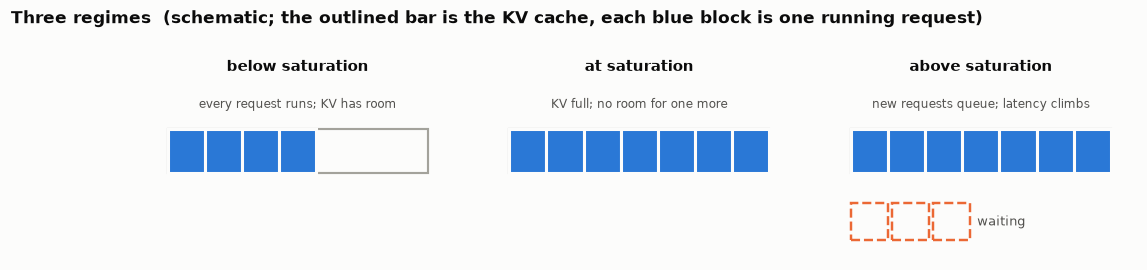

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(11.5, 2.6))
for ax, (name, run, wait, note) in zip(axes, [("below saturation", 4, 0, "every request runs;\nKV has room"),
                                             ("at saturation", 7, 0, "KV full;\nno room for one more"),
                                             ("above saturation", 7, 3, "new requests queue;\nlatency climbs")]):
    ax.set_xlim(0, 8); ax.set_ylim(0, 3.2); ax.axis("off")
    ax.add_patch(Rectangle((0.3, 1.4), 7.0, 0.7, fc="none", ec=G2, lw=1.4))
    for k in range(run):
        ax.add_patch(Rectangle((0.3 + k, 1.4), 1.0, 0.7, fc=BLUE, ec=SURFACE, lw=2))
    for k in range(wait):
        ax.add_patch(Rectangle((0.3 + k * 1.1, 0.3), 1.0, 0.6, fc=SURFACE, ec=ORANGE, lw=1.6, ls="--"))
    if wait: ax.text(3.7, 0.6, "waiting", fontsize=8.5, color=INK2, va="center")
    ax.text(3.8, 3.05, name, ha="center", fontsize=10, fontweight="bold")
    ax.text(3.8, 2.45, note.replace("\n", " "), ha="center", fontsize=8, color=INK2)
fig.suptitle("Three regimes  (schematic; the outlined bar is the KV cache, each blue block is one running request)",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.subplots_adjust(wspace=0.15, top=0.8)
plt.show()

**Try it.** Using your `share` from Chapter 1 and your `N_kv` values from Chapter 4: at about how many agents does KV run out,
for mean-sized requests? For p90-sized requests? Then run the next cell.

KV runs out at about  39.1 agents, for requests of size mean resident (W4)
KV runs out at about  24.1 agents, for requests of size p90 (W6)
KV runs out at about   9.4 agents, for requests of size max (W7)


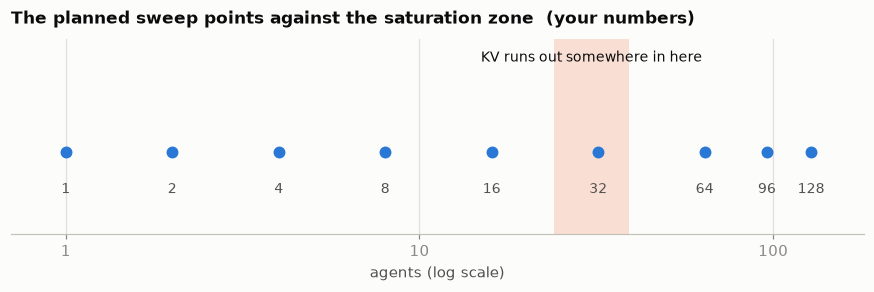

In [43]:
SWEEP = [1, 2, 4, 8, 16, 32, 64, 96, 128]     # the planned agent counts from the checklist
if CALLS and W1:
    A_SAT = {k: v / MODEL_SHARE for k, v in N_KV.items()}
    for k, v in A_SAT.items():
        print(f"KV runs out at about {v:5.1f} agents, for requests of size {k}")
    lo, hi = sorted([A_SAT["p90 (W6)"], A_SAT["mean resident (W4)"]])
    fig, ax = plt.subplots(figsize=(10, 2.3))
    ax.set_xscale("log"); plain_log(ax.xaxis, [1, 10, 100]); ax.set_ylim(-1, 1.4); ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.axvspan(lo, hi, color=ORANGE, alpha=0.2, linewidth=0)
    ax.text((lo * hi) ** 0.5, 1.12, "KV runs out somewhere in here", ha="center", fontsize=9)
    ax.scatter(SWEEP, [0] * len(SWEEP), s=46, color=BLUE, zorder=3)
    for c in SWEEP: ax.text(c, -0.5, str(c), ha="center", fontsize=9, color=INK2)
    ax.set_xlim(0.7, 180); ax.set_xlabel("agents (log scale)"); ax.grid(axis="x", color=GRID, linewidth=0.8)
    title(ax, "The planned sweep points against the saturation zone  (your numbers)")
    plt.show()

**A second opinion, from your real runs.** The estimate above uses averages. This simulation stacks `c` agents, each
replaying random real runs back to back from a random starting point, and adds up the KV they hold at every moment. Where the
**p99** line crosses the capacity line, KV is full about 1% of the time.

It assumes calls take as long as they did at concurrency 1. Under load they get slower, so agents stay inside model calls
longer and saturation comes **earlier** than this shows.

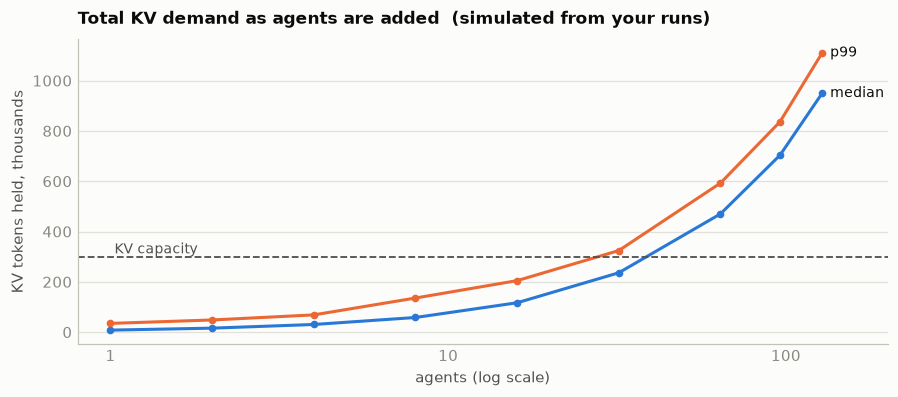

In [44]:
OCC = [occupancy(a) for a in AGENTS]
def simulate(c, T=600.0, warm=120.0, seed=0):
    rng = np.random.default_rng(seed); n = int(T / DT); total = np.zeros(n)
    for _ in range(c):
        i = -int(rng.uniform(0, 20) / DT)
        while i < n:
            occ = OCC[rng.integers(len(OCC))]; lo_, hi_ = max(i, 0), min(i + len(occ), n)
            if hi_ > lo_: total[lo_:hi_] += occ[lo_ - i:hi_ - i]
            i += len(occ)
    return total[int(warm / DT):]

if OCC:
    sims = {c: simulate(c) for c in SWEEP}
    k = 1000.0
    fig, ax = plt.subplots(figsize=(9.5, 3.6))
    for q, color, name in [(50, BLUE, "median"), (99, ORANGE, "p99")]:
        ys = [np.percentile(sims[c], q) / k for c in SWEEP]
        ax.plot(SWEEP, ys, color=color, lw=2, marker="o", ms=4); ax.text(SWEEP[-1], ys[-1], f"  {name}", va="center", fontsize=9)
    if W1:
        ax.axhline(W1 / k, color=INK2, ls="--", lw=1.2); ax.text(1, W1 / k, " KV capacity", va="bottom", fontsize=9, color=INK2)
    ax.set_xscale("log"); plain_log(ax.xaxis, [1, 10, 100]); ax.set_xlim(0.8, 200)
    ax.set_xlabel("agents (log scale)"); ax.set_ylabel("KV tokens held, thousands"); style(ax)
    title(ax, "Total KV demand as agents are added  (simulated from your runs)")
    plt.show()

**Why it matters next.**

- **Sweep points:** put several agent counts inside and around the zone, plus a few below it (the linear regime) and a couple
  well above it (to see the queueing). Points far above the zone mostly measure queueing, so you can thin them out.
- **`max_num_seqs`:** it caps how many requests run at once. Above the KV ceiling it only adds preemption, and well below it, it
  leaves memory unused. A loose range is about **0.5x to 2x** of the ceiling you computed.
- **What to watch in the sweep:** `num_requests_running`, `num_requests_waiting`, KV usage, preemptions, queue time and p90 task time.
  The knee is where generation tokens/s stops climbing while latency keeps rising.

## Chapter 6: how does the scheduler mix prefill and decode?

**The question.** With many agents, some requests are prefilling a long prompt while others are decoding. vLLM runs both
in the **same engine step**. How does it share a step, and what does `max_num_batched_tokens` control?

Each engine step processes a budget of tokens: one token for each decoding request, plus a **chunk** of some request's
prompt. `max_num_batched_tokens` is that budget. A long prompt is cut into chunks that fit (**chunked prefill**). While a big chunk
is in the step, every decoding request waits for it, so their next token is late.

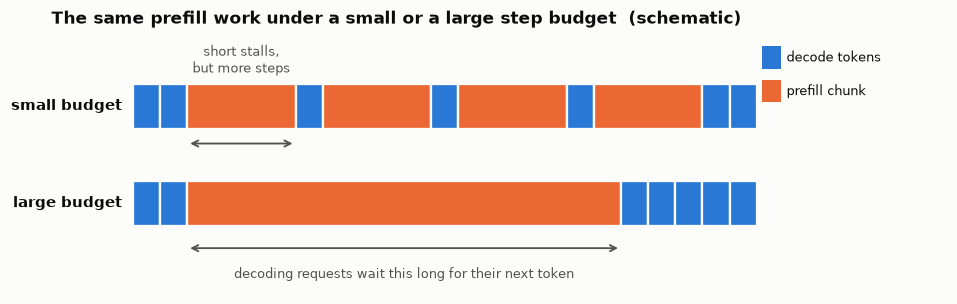

In [45]:
fig, ax = plt.subplots(figsize=(10.5, 3.0))
ax.set_xlim(-1.5, 15); ax.set_ylim(0, 3.4); ax.axis("off")
def lane(y, parts, lab):
    ax.text(-0.2, y + 0.3, lab, ha="right", va="center", fontsize=9.5, fontweight="bold"); x = 0.0
    for kind, w in parts:
        ax.add_patch(Rectangle((x, y), w, 0.6, fc=ORANGE if kind == "P" else BLUE, ec=SURFACE, lw=1.5)); x += w
lane(2.2, [("D", .5)] * 2 + [("P", 2), ("D", .5)] * 4 + [("D", .5)], "small budget")
lane(0.9, [("D", .5)] * 2 + [("P", 8)] + [("D", .5)] * 5, "large budget")
ax.annotate("", xy=(9.0, 0.6), xytext=(1.0, 0.6), arrowprops=dict(arrowstyle="<->", color=INK2, lw=1.2))
ax.text(5.0, 0.2, "decoding requests wait this long for their next token", ha="center", fontsize=8.5, color=INK2)
ax.annotate("", xy=(3.0, 2.0), xytext=(1.0, 2.0), arrowprops=dict(arrowstyle="<->", color=INK2, lw=1.2))
ax.text(2.0, 2.95, "short stalls,\nbut more steps", ha="center", fontsize=8.5, color=INK2)
ax.add_patch(Rectangle((11.6, 3.0), 0.35, 0.3, fc=BLUE)); ax.text(12.05, 3.15, "decode tokens", va="center", fontsize=8.5)
ax.add_patch(Rectangle((11.6, 2.55), 0.35, 0.3, fc=ORANGE)); ax.text(12.05, 2.7, "prefill chunk", va="center", fontsize=8.5)
title(ax, "The same prefill work under a small or a large step budget  (schematic)")
plt.show()

**How big are the prompts that need prefilling?** The size that matters is the **new** part of each call's prompt: the growth since the
previous call (or the whole first prompt). The dashed lines are candidate budgets from the checklist. A budget only changes
anything for calls bigger than it.

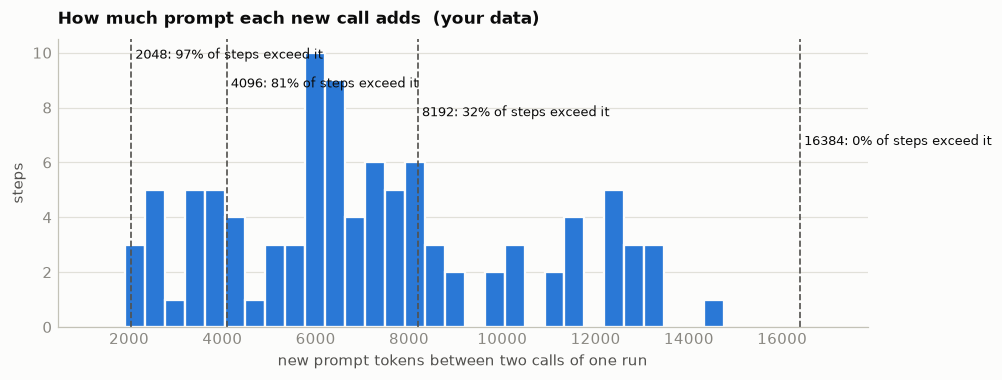

In [46]:
B_CANDS = [2048, 4096, 8192, 16384]
growth = [b["prompt"] - a["prompt"] for ag in AGENTS for a, b in zip(ag["model"], ag["model"][1:])]
if growth:
    fig, ax = plt.subplots(figsize=(9.5, 3.4))
    ax.hist(growth, bins=30, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
    top = ax.get_ylim()[1]
    for i, B in enumerate(B_CANDS):
        if B < max(growth) * 1.3:
            ax.axvline(B, color=INK2, ls="--", lw=1.1); ax.text(B, top * (0.97 - 0.1 * i), f" {B}: {100 * np.mean(np.array(growth) > B):.0f}% of steps exceed it", va="top", fontsize=8.5)
    ax.margins(x=0.1); ax.set_xlabel("new prompt tokens between two calls of one run"); ax.set_ylabel("steps"); style(ax)
    title(ax, "How much prompt each new call adds  (your data)")
    plt.show()

**Try it.** A full chunk of `B` tokens takes about `B / prefill speed` (Chapter 2's server number). Compare it with one normal
decode step (the ITL). For the current setting (`B = 8192`), how many times longer than a normal token does a decoding request
wait during a full chunk? Then run the next cell.

In [47]:
if SRV:
    pf = SRV["vllm:request_prefill_kv_computed_tokens_sum"] / SRV["vllm:request_prefill_time_seconds_sum"]
    itl_ms = 1000 * hmean("vllm:inter_token_latency_seconds")
    print(f"prefill speed {pf:,.0f} tokens/s, normal decode step {itl_ms:.1f} ms\n")
    print(f"{'budget B':>9}{'full chunk (ms)':>17}{'x a normal token':>18}")
    for B in B_CANDS:
        ch = B / pf * 1000
        print(f"{B:>9}{ch:>17.0f}{ch / itl_ms:>17.1f}x")
    print(f"\nmean tokens per engine step in your passes: {hmean('vllm:iteration_tokens_total'):.0f}  "
          "(at concurrency 1 most steps are a single decode token)")

prefill speed 13,564 tokens/s, normal decode step 15.5 ms

 budget B  full chunk (ms)  x a normal token
     2048              151              9.8x
     4096              302             19.5x
     8192              604             39.0x
    16384             1208             78.0x

mean tokens per engine step in your passes: 9  (at concurrency 1 most steps are a single decode token)


**Why it matters next.** `max_num_batched_tokens` trades **TTFT** (a bigger budget prefills a long prompt in fewer steps) against
**ITL jitter for everyone else** (a bigger chunk is a longer stall). The total prefill work doesn't change. At concurrency 1 it hardly
matters, since nobody else is decoding. It starts to matter when many agents are decoding while others send 5 to 10k-token prompts.
A loose range is the checklist's 2k to 16k, centred on where the big new prompts sit in the histogram above.

## Chapter 7: where does the GPU's time go? (the road to a kernel)

**The question.** A custom kernel only helps if it speeds up the part of each engine step that actually takes the time. What
limits a step: arithmetic, or reading memory?

Every engine step does two kinds of work:

- **Matrix multiplies with the weights** (attention projections and the MLP). The weights are read **once per step**, no matter
  how many sequences are in the batch. More sequences per step means more arithmetic for the same bytes.
- **Attention over the KV cache.** Each sequence reads **its own** KV cache. That cost grows with batch size and context length,
  and is **not** shared between sequences.

The useful ratio is **arithmetic intensity**: FLOPs done per byte read. A GPU can do about `peak FLOP/s / peak bytes/s` FLOPs
per byte (the *ridge point*). Below it, a step is **memory-bound**; above it, **compute-bound**.

**Where the 32B weights come from.** From the config, the parameter count is roughly:

```
per layer:  attention = hidden x (q heads x head size)  +  2 x hidden x (KV heads x head size)  +  (q heads x head size) x hidden
            MLP       = 3 x hidden x intermediate          (gate, up and down projections)
total     = layers x per layer  +  embeddings (vocab x hidden, twice if input and output aren't tied)
```

(This ignores small terms such as norms.) **Try it**, then run the next cell.

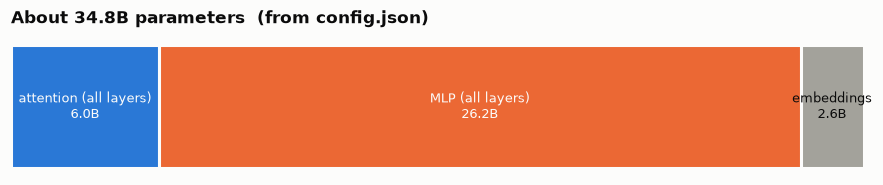

in bf16 that is 64.8 GiB, 32.4 GiB per GPU  (the startup log says 32.74 GiB per GPU for weights + non-torch)


In [48]:
if CFG:
    H, I, V = CFG["hidden_size"], CFG["intermediate_size"], CFG["vocab_size"]
    attn = H * QH * HD + 2 * H * KVH * HD + QH * HD * H
    mlp = 3 * H * I
    emb = V * H * (1 if CFG.get("tie_word_embeddings") else 2)
    P = L * (attn + mlp) + emb
    parts = {"attention (all layers)": L * attn, "MLP (all layers)": L * mlp, "embeddings": emb}
    fig, ax = plt.subplots(figsize=(10, 1.6))
    left = 0
    for (name, n), c in zip(parts.items(), [BLUE, ORANGE, G2]):
        ax.barh(0, n / 1e9, left=left, color=c, edgecolor=SURFACE, linewidth=2, height=0.6)
        ax.text(left + n / 2e9, 0, f"{name}\n{n / 1e9:.1f}B", ha="center", va="center", fontsize=8.5, color=SURFACE if c != G2 else INK)
        left += n / 1e9
    ax.set_xlim(0, left); ax.axis("off"); title(ax, f"About {P / 1e9:.1f}B parameters  (from config.json)")
    plt.show()
    WEIGHT_BYTES_GPU = P * 2 / TP
    print(f"in bf16 that is {P * 2 / 2**30:.1f} GiB, {WEIGHT_BYTES_GPU / 2**30:.1f} GiB per GPU"
          + (f"  (the startup log says {BOOT['weights']} GiB per GPU for weights + non-torch)" if BOOT["weights"] else ""))

**Try it: is decode at concurrency 1 limited by memory?** At batch size 1, each decode step reads every weight on the GPU once,
plus this request's KV cache. If the step were purely limited by memory bandwidth, it would take

```
time per step  ~  (weight bytes per GPU  +  context x KV bytes per token / N_GPU)  /  memory bandwidth
```

Use the mean context from Chapter 4 and the H100's ~3.35 TB/s. How does that compare with your measured ITL? What bandwidth
does your measured ITL imply? Then run the next cell.

In [49]:
if CFG and SRV and CALLS:
    ctx = R["mean resident (W4)"]
    bytes_step = WEIGHT_BYTES_GPU + ctx * KV_BYTES / TP
    t_ideal = bytes_step / (PEAK_HBM_TBPS * 1e12) * 1000
    print(f"bytes read per decode step per GPU: {bytes_step / 1e9:.1f} GB (weights {WEIGHT_BYTES_GPU / 1e9:.1f} + KV {ctx * KV_BYTES / TP / 1e9:.2f})"
          "   [GB = 10^9 bytes here, to match TB/s]")
    print(f"if limited only by memory bandwidth:  {t_ideal:.1f} ms per token")
    print(f"measured ITL:                         {itl_ms:.1f} ms per token")
    print(f"implied bandwidth: {bytes_step / (itl_ms / 1000) / 1e12:.2f} TB/s per GPU = {100 * t_ideal / itl_ms:.0f}% of the peak")
    print("\nThe rest of the gap is time that isn't reading memory: the all-reduce between the GPUs every layer, kernel launches, and so on.")

bytes read per decode step per GPU: 35.9 GB (weights 34.8 + KV 1.09)   [GB = 10^9 bytes here, to match TB/s]
if limited only by memory bandwidth:  10.7 ms per token
measured ITL:                         15.5 ms per token
implied bandwidth: 2.32 TB/s per GPU = 69% of the peak

The rest of the gap is time that isn't reading memory: the all-reduce between the GPUs every layer, kernel launches, and so on.


**The roofline: how batching changes the picture.** Each point is one kind of engine step, placed by its arithmetic intensity.
Its height is the best performance the hardware allows for that intensity. Decode at batch 1 sits far down the memory-bound
slope. Batching sequences together moves decode right, because the weight reads are shared. But each sequence's KV reads are
not shared, so long contexts drag it back left. A large prefill chunk sits on the flat compute-bound roof.

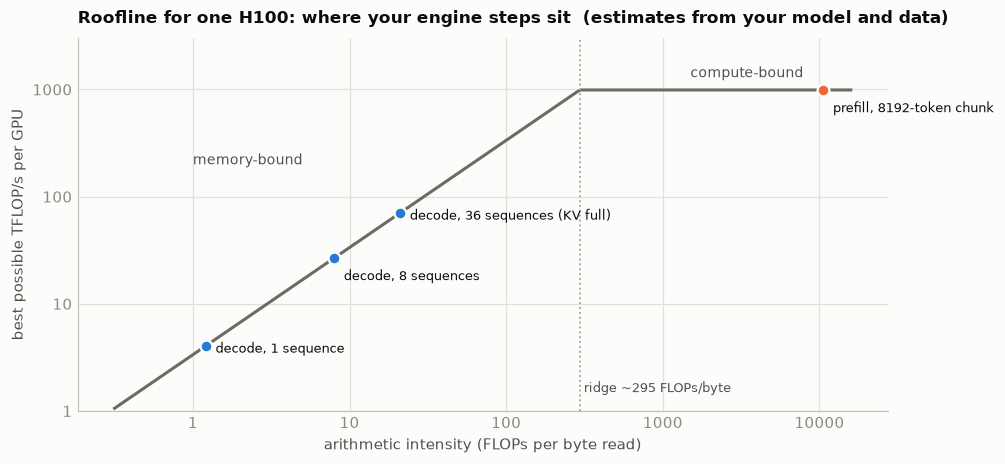

  decode, 1 sequence                   intensity      1.2 FLOPs/byte  -> memory-bound
  decode, 8 sequences                  intensity      8.0 FLOPs/byte  -> memory-bound
  decode, 36 sequences (KV full)       intensity     21.1 FLOPs/byte  -> memory-bound
  prefill, 8192-token chunk            intensity  10605.4 FLOPs/byte  -> compute-bound


In [50]:
if CFG and CALLS:
    ridge = PEAK_TFLOPS_BF16 / PEAK_HBM_TBPS
    attn_flops_tok = 4 * L * QH * HD          # attention FLOPs per (token, context token): QK^T and PV, 2 FLOPs per multiply-add
    def decode_point(b, ctx):
        flops = 2 * P * b + attn_flops_tok * ctx * b
        bytes_ = 2 * P + b * ctx * KV_BYTES
        return flops / bytes_
    def prefill_point(B, ctx):
        flops = 2 * P * B + attn_flops_tok * B * (ctx + B / 2)
        bytes_ = 2 * P + (ctx + B) * KV_BYTES
        return flops / bytes_
    ctx = R["mean resident (W4)"]
    pts = [(f"decode, 1 sequence", decode_point(1, ctx), BLUE),
           (f"decode, 8 sequences", decode_point(8, ctx), BLUE)]
    if W1:
        b_sat = int(round(N_KV["mean resident (W4)"]))
        pts.append((f"decode, {b_sat} sequences (KV full)", decode_point(b_sat, ctx), BLUE))
    pts.append(("prefill, 8192-token chunk", prefill_point(8192, ctx), ORANGE))
    xs = np.logspace(-0.5, 4.2, 200)
    roof = np.minimum(PEAK_TFLOPS_BF16, xs * PEAK_HBM_TBPS)
    fig, ax = plt.subplots(figsize=(9.5, 4.4))
    ax.plot(xs, roof, color=G1, lw=2)
    ax.axvline(ridge, color=G2, ls=":", lw=1.2); ax.text(ridge, 1.5, f" ridge ~{ridge:.0f} FLOPs/byte", fontsize=8.5, color=INK2)
    for i, (name, x, c) in enumerate(pts):
        y = min(PEAK_TFLOPS_BF16, x * PEAK_HBM_TBPS)
        ax.scatter([x], [y], s=60, color=c, zorder=3, edgecolor=SURFACE, linewidth=1.5)
        ax.text(x * 1.15, y * (0.62 if i % 2 else 0.86), name, fontsize=8.5)
    ax.set_xscale("log"); ax.set_yscale("log")
    plain_log(ax.xaxis, [1, 10, 100, 1000, 10000]); plain_log(ax.yaxis, [1, 10, 100, 1000])
    ax.set_xlabel("arithmetic intensity (FLOPs per byte read)"); ax.set_ylabel("best possible TFLOP/s per GPU"); style(ax, "both")
    ax.text(1.0, 200, "memory-bound", fontsize=9, color=INK2); ax.text(1500, 1300, "compute-bound", fontsize=9, color=INK2)
    ax.set_ylim(1, 3000)
    title(ax, "Roofline for one H100: where your engine steps sit  (estimates from your model and data)")
    plt.show()
    for name, x, _ in pts:
        print(f"  {name:36} intensity {x:8.1f} FLOPs/byte  -> {'compute' if x > ridge else 'memory'}-bound")

**Why it matters next: what this says about a kernel.**

- **Decode is memory-bound**, even with the weight reads shared across a batch, because **attention's KV reads grow with every
  sequence and every token of context**. Decode attention is the part that does not get cheaper with batching. That makes it the
  natural first target for a custom kernel, along with anything that reads less KV per token (fp8 KV is one way).
- **Prefill is compute-bound.** It is mostly large matrix multiplies, which the vendor libraries already run close to peak. A custom
  kernel has less room to win there.
- **Don't trust these estimates for the decision.** They show where to look. The real decision comes from **profiling the best
  config under load** (section H of the checklist), which measures how long each kernel actually takes.

## Chapter 8: putting it together

Each knob, the physical thing it controls, and which of your numbers bound it:

| Knob | What it controls | The numbers that bound it | A loose range | Watch in the sweep |
|---|---|---|---|---|
| agent count | load | KV ceiling / share in model (ch. 5) | below, inside and above the saturation zone | tasks/min, p90, waiting |
| `max_num_seqs` | requests running at once | KV ceiling for mean and p90 requests (ch. 4) | ~0.5x to 2x the ceiling | running, preemptions |
| `max_num_batched_tokens` | tokens per engine step | new-prompt sizes vs chunk stall (ch. 6) | 2k to 16k | TTFT vs ITL |
| `gpu_memory_utilization` | memory for KV vs headroom | startup memory split (ch. 3) | up to what was free, minus your safety margin | KV capacity, OOM |
| `kv_cache_dtype` | bytes per KV token | bf16 vs fp8 (ch. 3, 7) | {auto, fp8} | KV capacity, ITL, answer quality |

Write down your loose bounds here, with a sentence each on why. Then define "best" (section F in `TODOChecklist.md`) before
the first sweep.

In [52]:
MY_BOUNDS = {
    "agent counts":            [1, 8, 16, 32, 64], # Anything more than 39 and we're going to start thrashing. Keeping 64 to see that happen
    "max_num_seqs":            [16, 32, 48, 64], # 0.5, 1.0, 1.5, 2.0 times the calculated max number of agents
    "max_num_batched_tokens":  4096, # this is the tradeoff between TTFT and ITL that comes from adding prefill between decode. Keep it around the start of the ridge cap?
    "gpu_memory_utilization":  0.9, # not the focus
    "kv_cache_dtype":          "bf16", # not the focus
}
WHY = {k: "" for k in MY_BOUNDS}
for k, v in MY_BOUNDS.items():
    print(f"{k:26}{'____' if v is None else v}   {WHY[k]}")

agent counts              [1, 8, 16, 32, 64]   
max_num_seqs              [16, 32, 48, 64]   
max_num_batched_tokens    4096   
gpu_memory_utilization    0.9   
kv_cache_dtype            bf16   
